## Google Colab Setup
1. Upload the full `NLPFinalProjectCode` folder to Google Drive.
2. Open this notebook in Google Colab.
3. In the setup cell below, update `PROJECT_DIR` if your Drive path is different.
4. Run the setup cell once to mount Drive and install the Colab package list from `requirements-colab.txt`.
5. Run the remaining cells from top to bottom.

This notebook expects the data to remain inside `data/droplet` and `data/annotations` under `PROJECT_DIR`.


In [1]:
import os
import sys
import subprocess
from pathlib import Path

RUNNING_IN_COLAB = "google.colab" in sys.modules

if RUNNING_IN_COLAB:
    from google.colab import drive

    PROJECT_DIR = Path("/content/drive/MyDrive/NLPFinalProjectCode")  # Update if your Drive path is different.
    drive.mount("/content/drive", force_remount=False)

    if not PROJECT_DIR.exists():
        raise FileNotFoundError(
            f"Set PROJECT_DIR to the folder containing this notebook and the data directory. Current value: {PROJECT_DIR}"
        )

    os.chdir(PROJECT_DIR)
    subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", "-r", "requirements-colab.txt"])
else:
    PROJECT_DIR = Path.cwd()
    if not (PROJECT_DIR / "data").exists() and (PROJECT_DIR / "NLPFinalProjectCode" / "data").exists():
        PROJECT_DIR = PROJECT_DIR / "NLPFinalProjectCode"
    PROJECT_DIR = PROJECT_DIR.resolve()
    os.chdir(PROJECT_DIR)

DATA_ROOT = str(PROJECT_DIR / "data" / "droplet")
ANNOTATIONS_DIR = str(PROJECT_DIR / "data" / "annotations")
OUT_PATH = str(PROJECT_DIR / "gene_rank_sentences.txt")

print("Project directory:", PROJECT_DIR)
print("Data root:", DATA_ROOT)
print("Annotations directory:", ANNOTATIONS_DIR)
print("Corpus output path:", OUT_PATH)


Project directory: /Users/naveenkumanan/Spring'26/NLP/FinalProject/NLPFinalProjectCode
Data root: /Users/naveenkumanan/Spring'26/NLP/FinalProject/NLPFinalProjectCode/data/droplet
Annotations directory: /Users/naveenkumanan/Spring'26/NLP/FinalProject/NLPFinalProjectCode/data/annotations
Corpus output path: /Users/naveenkumanan/Spring'26/NLP/FinalProject/NLPFinalProjectCode/gene_rank_sentences.txt


## Gene-Ranking as a "Sentence" (Cell = Document, Gene = Token)
This section builds a corpus where each cell is a sentence of its top-K expressed genes (after log-normalization).


In [2]:
from __future__ import annotations

import os
import glob
import numpy as np
import scanpy as sc
import scipy.sparse as sp

# ---- Config ----
USE_PREFIXES = []  # e.g., ["Bladder", "Heart"] or [] for all
TOP_K = 100
MAX_CELLS = None  # e.g., 5000 to subsample for speed; None for all

# ---- Load 10x droplet data ----
folders = sorted([p for p in glob.glob(os.path.join(DATA_ROOT, '*')) if os.path.isdir(p)])
if USE_PREFIXES:
    folders = [p for p in folders if any(os.path.basename(p).startswith(pref) for pref in USE_PREFIXES)]

if not folders:
    raise ValueError(f"No droplet folders found under {DATA_ROOT} with prefixes {USE_PREFIXES}")

adatas = []
keys = []
for folder in folders:
    key = os.path.basename(folder)
    ad = sc.read_10x_mtx(folder, var_names='gene_symbols', cache=False)
    ad.var_names_make_unique()
    adatas.append(ad)
    keys.append(key)

adata = sc.concat(adatas, label='sample', keys=keys, index_unique='-')
print(adata)

# ---- Normalize (log1p) ----
sc.pp.normalize_total(adata, target_sum=1e4)
sc.pp.log1p(adata)


/Users/naveenkumanan/miniconda3/envs/myenv/lib/python3.12/site-packages/louvain/__init__.py:54: UserWarning: pkg_resources is deprecated as an API. See https://setuptools.pypa.io/en/latest/pkg_resources.html. The pkg_resources package is slated for removal as early as 2025-11-30. Refrain from using this package or pin to Setuptools<81.
  from pkg_resources import get_distribution, DistributionNotFound


AnnData object with n_obs × n_vars = 1508710 × 23433
    obs: 'sample'


/Users/naveenkumanan/miniconda3/envs/myenv/lib/python3.12/site-packages/legacy_api_wrap/__init__.py:82: UserWarning: Some cells have zero counts
  return fn(*args_all, **kw)


In [3]:
# ---- Build gene-ranked sentences ----
def topk_gene_indices(row, k: int):
    if sp.issparse(row):
        row = row.tocsr()
        data = row.data
        idx = row.indices
        if data.size == 0:
            return np.array([], dtype=int)
        if data.size > k:
            top = np.argpartition(data, -k)[-k:]
            order = top[np.argsort(data[top])[::-1]]
            return idx[order]
        order = np.argsort(data)[::-1]
        return idx[order]
    else:
        arr = np.asarray(row).ravel()
        if arr.size == 0:
            return np.array([], dtype=int)
        if k < arr.size:
            idx = np.argpartition(arr, -k)[-k:]
            idx = idx[np.argsort(arr[idx])[::-1]]
        else:
            idx = np.argsort(arr)[::-1]
        return idx[arr[idx] > 0]

X = adata.X
var_names = np.array(adata.var_names)

# Optional subsample for speed
cell_indices = np.arange(adata.n_obs)
if MAX_CELLS is not None and adata.n_obs > MAX_CELLS:
    rng = np.random.default_rng(0)
    cell_indices = rng.choice(cell_indices, size=MAX_CELLS, replace=False)

sentences = []
for i in cell_indices:
    row = X[i]
    idx = topk_gene_indices(row, TOP_K)
    tokens = var_names[idx]
    sentences.append(' '.join(tokens))

print('num_sentences:', len(sentences))
print('example:', sentences[0][:200])


num_sentences: 1508710
example: Malat1 Ftl1 Col1a2 Junb Dcn Fos Rpl41 Col1a1 Gsn Col3a1 Actb Eef1a1 Rpl13 Tpt1 Rn45s Rpl13a Rplp0 Rps23 Rplp1 Tmsb10 Socs3 Rps19 Rpl35 Egr1 Rps29 Rps4x Gadd45g Rpl37a Rps5 Mt1 Rpl6 Rpl18a Rpl37 Rps28 


In [4]:
# ---- (Optional) Save corpus to disk ----
with open(OUT_PATH, 'w') as f:
    for s in sentences:
        f.write(s + '\n')
print('wrote:', OUT_PATH)


wrote: /Users/naveenkumanan/Spring'26/NLP/FinalProject/NLPFinalProjectCode/gene_rank_sentences.txt


## Labels + Embedding Model for Cell Type Annotation
This section aligns cells to Tabula Muris annotations and trains a simple embedding-based classifier.


In [5]:
import csv

# ---- Load organ-specific annotations ----
# If USE_PREFIXES is set (e.g., ['Lung']), load only those organ annotation files.
# Otherwise, load all '*_droplet_annotation.csv' files in the folder.
if USE_PREFIXES:
    ann_files = [os.path.join(ANNOTATIONS_DIR, f"{org}_droplet_annotation.csv") for org in USE_PREFIXES]
else:
    ann_files = [
        os.path.join(ANNOTATIONS_DIR, f)
        for f in os.listdir(ANNOTATIONS_DIR)
        if f.endswith('_droplet_annotation.csv')
    ]

labels = {}
label_col = 'cell_ontology_class'

for fp in ann_files:
    if not os.path.exists(fp):
        print('missing annotation file:', fp)
        continue
    with open(fp, newline='') as f:
        reader = csv.DictReader(f)
        for row in reader:
            cell = row['cell']  # format: 10X_P7_8_AAAC...
            tissue = row['tissue']
            parts = cell.split('_')
            barcode = parts[-1]
            if not barcode.endswith('-1'):
                barcode = barcode + '-1'
            channel = '_'.join(parts[:3])
            obs_name = f"{barcode}-{tissue}-{channel}"
            labels[obs_name] = row[label_col]

# Align sentences with labels
sentence_indices = cell_indices
obs_names = adata.obs_names[sentence_indices]

sentences_labeled = []
labels_labeled = []
for obs, sent in zip(obs_names, sentences):
    lab = labels.get(obs)
    if lab is not None and lab != '':
        sentences_labeled.append(sent)
        labels_labeled.append(lab)

print('labeled_sentences:', len(sentences_labeled))

from collections import Counter
print('label examples:', Counter(labels_labeled).most_common(5))


labeled_sentences: 36849
label examples: [('B cell', 8317), ('T cell', 4422), ('stromal cell', 3237), ('endothelial cell', 1776), ('hepatocyte', 1764)]


In [6]:
# ---- Build vocab + encode sentences ----
SPECIAL_TOKENS = ['<pad>', '<unk>']

all_tokens = [tok for s in sentences_labeled for tok in s.split()]
vocab = {tok: i + len(SPECIAL_TOKENS) for i, tok in enumerate(sorted(set(all_tokens)))}
for i, tok in enumerate(SPECIAL_TOKENS):
    vocab[tok] = i

inv_vocab = {i: tok for tok, i in vocab.items()}

def encode_sentence(s, k=TOP_K):
    toks = s.split()[:k]
    ids = [vocab.get(t, vocab['<unk>']) for t in toks]
    if len(ids) < k:
        ids = ids + [vocab['<pad>']] * (k - len(ids))
    return ids

X_ids = np.array([encode_sentence(s) for s in sentences_labeled], dtype=np.int64)

# label encoding
label_set = sorted(set(labels_labeled))
label_to_id = {lab: i for i, lab in enumerate(label_set)}
y = np.array([label_to_id[lab] for lab in labels_labeled], dtype=np.int64)
label_names = label_set

print('vocab_size:', len(vocab))
print('num_classes:', len(label_names))


vocab_size: 7543
num_classes: 53


In [7]:
# ---- Train/val/test split ----
from sklearn.model_selection import train_test_split

X_train, X_temp, y_train, y_temp = train_test_split(X_ids, y, test_size=0.3, random_state=0, stratify=y)
X_val, X_test, y_val, y_test = train_test_split(X_temp, y_temp, test_size=0.5, random_state=0, stratify=y_temp)

print('train/val/test:', X_train.shape, X_val.shape, X_test.shape)


train/val/test: (25794, 100) (5527, 100) (5528, 100)


In [8]:
import torch
import torch.nn as nn
from torch.utils.data import Dataset, DataLoader

class GeneDataset(Dataset):
    def __init__(self, X, y):
        self.X = torch.tensor(X, dtype=torch.long)
        self.y = torch.tensor(y, dtype=torch.long)
    def __len__(self):
        return len(self.X)
    def __getitem__(self, idx):
        return self.X[idx], self.y[idx]

class BiLSTMClassifier(nn.Module):
    def __init__(self, vocab_size, emb_dim, hidden_dim, num_classes, pad_idx=0):
        super().__init__()
        self.emb = nn.Embedding(vocab_size, emb_dim, padding_idx=pad_idx)
        self.lstm = nn.LSTM(
            input_size=emb_dim,
            hidden_size=hidden_dim,
            batch_first=True,
            bidirectional=True,
        )
        self.fc = nn.Sequential(
            nn.Linear(2 * hidden_dim, 128),
            nn.ReLU(),
            nn.Dropout(0.2),
            nn.Linear(128, num_classes),
        )
    def forward(self, x):
        emb = self.emb(x)
        _, (h_n, _) = self.lstm(emb)
        # Concatenate the final forward and backward states for an order-sensitive readout.
        pooled = torch.cat([h_n[-2], h_n[-1]], dim=1)
        return self.fc(pooled)

BATCH_SIZE = 256
EMB_DIM = 64
HIDDEN_DIM = 64
EPOCHS = 5
LR = 1e-3

train_loader = DataLoader(GeneDataset(X_train, y_train), batch_size=BATCH_SIZE, shuffle=True)
val_loader = DataLoader(GeneDataset(X_val, y_val), batch_size=BATCH_SIZE)
test_loader = DataLoader(GeneDataset(X_test, y_test), batch_size=BATCH_SIZE)

device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
model = BiLSTMClassifier(len(vocab), EMB_DIM, HIDDEN_DIM, len(label_names)).to(device)
optimizer = torch.optim.Adam(model.parameters(), lr=LR)
criterion = nn.CrossEntropyLoss()


In [9]:
# ---- Train + evaluate ----
from sklearn.metrics import accuracy_score, f1_score

def run_eval(loader):
    model.eval()
    all_preds = []
    all_true = []
    with torch.no_grad():
        for xb, yb in loader:
            xb = xb.to(device)
            yb = yb.to(device)
            logits = model(xb)
            preds = torch.argmax(logits, dim=1)
            all_preds.append(preds.cpu().numpy())
            all_true.append(yb.cpu().numpy())
    y_true = np.concatenate(all_true)
    y_pred = np.concatenate(all_preds)
    return accuracy_score(y_true, y_pred), f1_score(y_true, y_pred, average='macro')

for epoch in range(1, EPOCHS + 1):
    model.train()
    for xb, yb in train_loader:
        xb = xb.to(device)
        yb = yb.to(device)
        optimizer.zero_grad()
        logits = model(xb)
        loss = criterion(logits, yb)
        loss.backward()
        optimizer.step()
    acc, f1 = run_eval(val_loader)
    print(f'Epoch {epoch}: val_acc={acc:.4f}, val_f1={f1:.4f}')

test_acc, test_f1 = run_eval(test_loader)
print(f'Test: acc={test_acc:.4f}, f1={test_f1:.4f}')


Epoch 1: val_acc=0.7176, val_f1=0.2295
Epoch 2: val_acc=0.8350, val_f1=0.4419
Epoch 3: val_acc=0.8723, val_f1=0.5671
Epoch 4: val_acc=0.8938, val_f1=0.6264
Epoch 5: val_acc=0.9094, val_f1=0.6903
Test: acc=0.9092, f1=0.6849


## Order Sensitivity Control (Shuffle Test)
This section tests whether gene order matters for cell-type prediction. We create a shuffled version of each gene sequence (preserving the same tokens but randomizing their order), then train the same BiLSTM model on both ordered and shuffled data. If performance drops on the shuffled sequences, ordering carries predictive signal.


In [10]:
import numpy as np

def shuffle_sequences(X_ids, pad_idx=0, seed=0):
    rng = np.random.default_rng(seed)
    X_shuf = X_ids.copy()
    for i in range(X_shuf.shape[0]):
        row = X_shuf[i]
        # shuffle only non-pad tokens
        mask = row != pad_idx
        tokens = row[mask]
        rng.shuffle(tokens)
        row[mask] = tokens
        X_shuf[i] = row
    return X_shuf

X_ids_shuffled = shuffle_sequences(X_ids, pad_idx=vocab['<pad>'], seed=0)
print('shuffled shape:', X_ids_shuffled.shape)


shuffled shape: (36849, 100)


Ordered -> Test acc=0.9137, f1=0.7100
Shuffled -> Test acc=0.7580, f1=0.2909


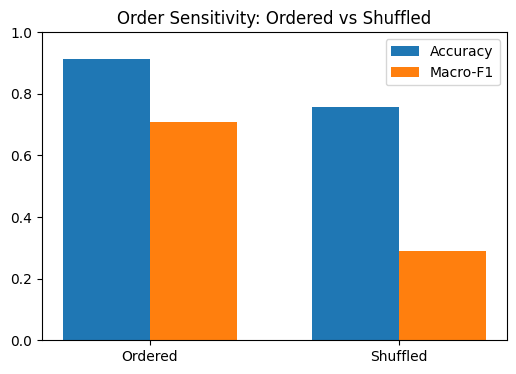

In [11]:
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score, f1_score
import matplotlib.pyplot as plt

def train_and_eval(X_ids_local, y_local, label):
    # split
    X_train, X_temp, y_train, y_temp = train_test_split(
        X_ids_local, y_local, test_size=0.3, random_state=0, stratify=y_local
    )
    X_val, X_test, y_val, y_test = train_test_split(
        X_temp, y_temp, test_size=0.5, random_state=0, stratify=y_temp
    )

    train_loader = DataLoader(GeneDataset(X_train, y_train), batch_size=BATCH_SIZE, shuffle=True)
    val_loader = DataLoader(GeneDataset(X_val, y_val), batch_size=BATCH_SIZE)
    test_loader = DataLoader(GeneDataset(X_test, y_test), batch_size=BATCH_SIZE)

    model = BiLSTMClassifier(len(vocab), EMB_DIM, HIDDEN_DIM, len(label_names)).to(device)
    optimizer = torch.optim.Adam(model.parameters(), lr=LR)
    criterion = nn.CrossEntropyLoss()

    def run_eval(loader):
        model.eval()
        all_preds, all_true = [], []
        with torch.no_grad():
            for xb, yb in loader:
                xb = xb.to(device)
                yb = yb.to(device)
                logits = model(xb)
                preds = torch.argmax(logits, dim=1)
                all_preds.append(preds.cpu().numpy())
                all_true.append(yb.cpu().numpy())
        y_true = np.concatenate(all_true)
        y_pred = np.concatenate(all_preds)
        return accuracy_score(y_true, y_pred), f1_score(y_true, y_pred, average='macro')

    for epoch in range(1, EPOCHS + 1):
        model.train()
        for xb, yb in train_loader:
            xb = xb.to(device)
            yb = yb.to(device)
            optimizer.zero_grad()
            logits = model(xb)
            loss = criterion(logits, yb)
            loss.backward()
            optimizer.step()
    test_acc, test_f1 = run_eval(test_loader)
    print(f'{label} -> Test acc={test_acc:.4f}, f1={test_f1:.4f}')
    return test_acc, test_f1

results = {}
results['Ordered'] = train_and_eval(X_ids, y, 'Ordered')
results['Shuffled'] = train_and_eval(X_ids_shuffled, y, 'Shuffled')

# Plot comparison
labels = list(results.keys())
accs = [results[k][0] for k in labels]
f1s = [results[k][1] for k in labels]

x = np.arange(len(labels))
width = 0.35
fig, ax = plt.subplots(figsize=(6,4))
ax.bar(x - width/2, accs, width, label='Accuracy')
ax.bar(x + width/2, f1s, width, label='Macro-F1')
ax.set_xticks(x)
ax.set_xticklabels(labels)
ax.set_ylim(0, 1)
ax.set_title('Order Sensitivity: Ordered vs Shuffled')
ax.legend()
plt.show()
